In [1]:
import glob
from datetime import datetime, timezone
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import xarray as xr
import cmdline_provenance as cmdprov

from unseen import fileio
from unseen import eva
from unseen import stability
from unseen import independence
from unseen import bias_correction
from unseen import general_utils
from unseen import similarity
from unseen import spatial_selection

In [2]:
model = 'IPSL-CM6A-LR'
var = 'pr'
levels_dict = {}
levels_dict[var] = np.arange(0, 701, 50)
levels_dict['psl'] = np.arange(900, 1100, 3)
levels_dict['zg500'] = np.arange(5000, 6300, 50)
var_cmap = 'YlGnBu'
metric = 'prJA'
metric_long = 'July-August accumulated rainfall'
units = 'mm'
units_dict = {}
units_dict[var] = units
units_dict['psl'] = 'hPa'
units_dict['zg500'] = 'm'
correction_method = 'multiplicative'

region_name = 'CentralPakistan'
region_lat0 = -10 
region_lat1 = 60
region_lon0 = 40
region_lon1 = 160

map_proj = ccrs.PlateCarree(central_longitude=180)

box_name = 'Central Pakistan'
box_lat0 = 24
box_lat1 = 33
box_lon0 = 65
box_lon1 = 71

dist_min = 0
dist_max = 500

outdir = '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data'
obs_list = ['era5', 'mswep', 'cpc']
obs_file = {}
obs_file['era5'] = f'{outdir}/prJA_ERA5_1940-2025_annual_central-pakistan.nc'
obs_file['mswep'] = f'{outdir}/prJA_MSWEP_1979-2025_annual_central-pakistan.nc'
obs_file['cpc'] = f'{outdir}/prJA_CPC_1979-2025_annual_central-pakistan.nc'
model_file = f'{outdir}/prJA_IPSL-CM6A-LR-dcppA-hindcast_196101-201701_annual_central-pakistan.nc'

obs_name = {
    'era5': 'ERA5',
    'cpc': 'Climate Prediction Center (CPC) Global Unified Gauge-Based Analysis of Daily Precipitation',
    'mswep': 'Multi-Source Weighted-Ensemble Precipitation (MSWEP)',
}

obs_source = {
    'era5': 'https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=overview',
    'cpc': 'https://psl.noaa.gov/data/gridded/data.cpc.globalprecip.html',
    'mswep': 'https://www.gloh2o.org/',
}

code_url = 'https://github.com/ClimateVHT/unseen-projects/tree/master/project-wcrp-rx5day'
history_log = cmdprov.new_log(code_url=code_url)

global_attrs = {
    'institution': 'CSIRO',
    'method': 'UNSEEN',
    'event': 'Pakistan Floods (seasonal timescale)',
    'project': 'WCRP Common Event Attribution and Assessment',
    'contact': 'damien.irving@csiro.au',
    'source': model,
    'experiment': 'dcppA-hindcast',
    'references': 'Decadal Climate Prediction Project (DCPP): https://doi.org/10.5194/gmd-9-3751-2016. UNSEEN methodology: https://doi.org/10.1002/met.70118',
    'creation_date': datetime.now(timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ'),
    'history': history_log,
}
    

In [3]:
def get_encoding(ds, skip_vars=[]):
    """Output file encoding."""

    encoding = {}
    ds_vars = list(ds.coords) + list(ds.keys())
    for ds_var in ds_vars:
        if ds_var not in skip_vars:
            encoding[ds_var] = {'_FillValue': None}

    return encoding

In [4]:
def likelihood(data, event):
    """Calculate event likelihood"""

    nsamples = len(data)
    nexceedances = int(np.sum(data >= event))
    print(f'Exceednances: {nexceedances} in {nsamples} samples') 
    probability = nexceedances / nsamples
    return_period = 1. / probability
    percentile = (1 - probability) * 100
    print(f'{return_period:.0f} year return period')
    print(f'{percentile:.2f}% percentile')

## Read observations

In [5]:
obs_ds = {}
obs_2022_event = {}
obs_2022_event_per_day = {}
for obs in obs_list:
    obs_ds[obs] = fileio.open_dataset(obs_file[obs])
    obs_ds[obs] = obs_ds[obs].dropna("time")
    obs_2022_event[obs] = obs_ds[obs][var].sel(time=slice('2022-01-01', '2022-12-31')).values[0]
    obs_2022_event_per_day[obs] = obs_2022_event[obs] / 62 
    print(f'{obs}: {obs_2022_event[obs]:.1f} {units}')
    print(f'{obs}: {obs_2022_event_per_day[obs]:.1f} {units}/day')

era5: 405.3 mm
era5: 6.5 mm/day
mswep: 437.7 mm
mswep: 7.1 mm/day
cpc: 518.6 mm
cpc: 8.4 mm/day


## Read (and test) model data

In [6]:
model_ds = fileio.open_dataset(model_file)

In [7]:
model_ds = model_ds.compute()
model_ds

<xarray.Dataset> Size: 28kB
Dimensions:    (init_date: 57, ensemble: 10, lead_time: 10)
Coordinates:
  * ensemble   (ensemble) int64 80B 0 1 2 3 4 5 6 7 8 9
  * lead_time  (lead_time) int64 80B 0 1 2 3 4 5 6 7 8 9
  * init_date  (init_date) object 456B 1961-12-31 00:00:00 ... 2017-12-31 00:...
    time       (lead_time, init_date) object 5kB 1961-12-31 00:00:00 ... 2026...
Data variables:
    pr         (init_date, ensemble, lead_time) float32 23kB 171.6 ... 113.5
Attributes: (12/52)
    name:                   /ccc/work/cont003/gencmip6/flavoni/IGCM_OUT/IPSLC...
    Conventions:            CF-1.7 CMIP-6.2
    creation_date:          2019-03-29T14:40:36Z
    description:            A1 (and A2.1, A3.1, and A3.2) Decadal hindcasts b...
    title:                  IPSL-CM6A-LR model output prepared for CMIP6 / DC...
    activity_id:            DCPP
    ...                     ...
    branch_time_in_parent:  22280.0
    sub_experiment:         initialized near end of year 1960
    tracking_id:            hdl:21.14100/521eb460-8e4b-44d5-8010-e7b978713519
    further_info_url:       https://furtherinfo.es-doc.org/CMIP6.IPSL.IPSL-CM...
    sub_experiment_id:      s1960
    history:                Mon Nov 09 11:04:26 2026: /g/data/xv83/dbi599/min...

#### Stability and stationarity

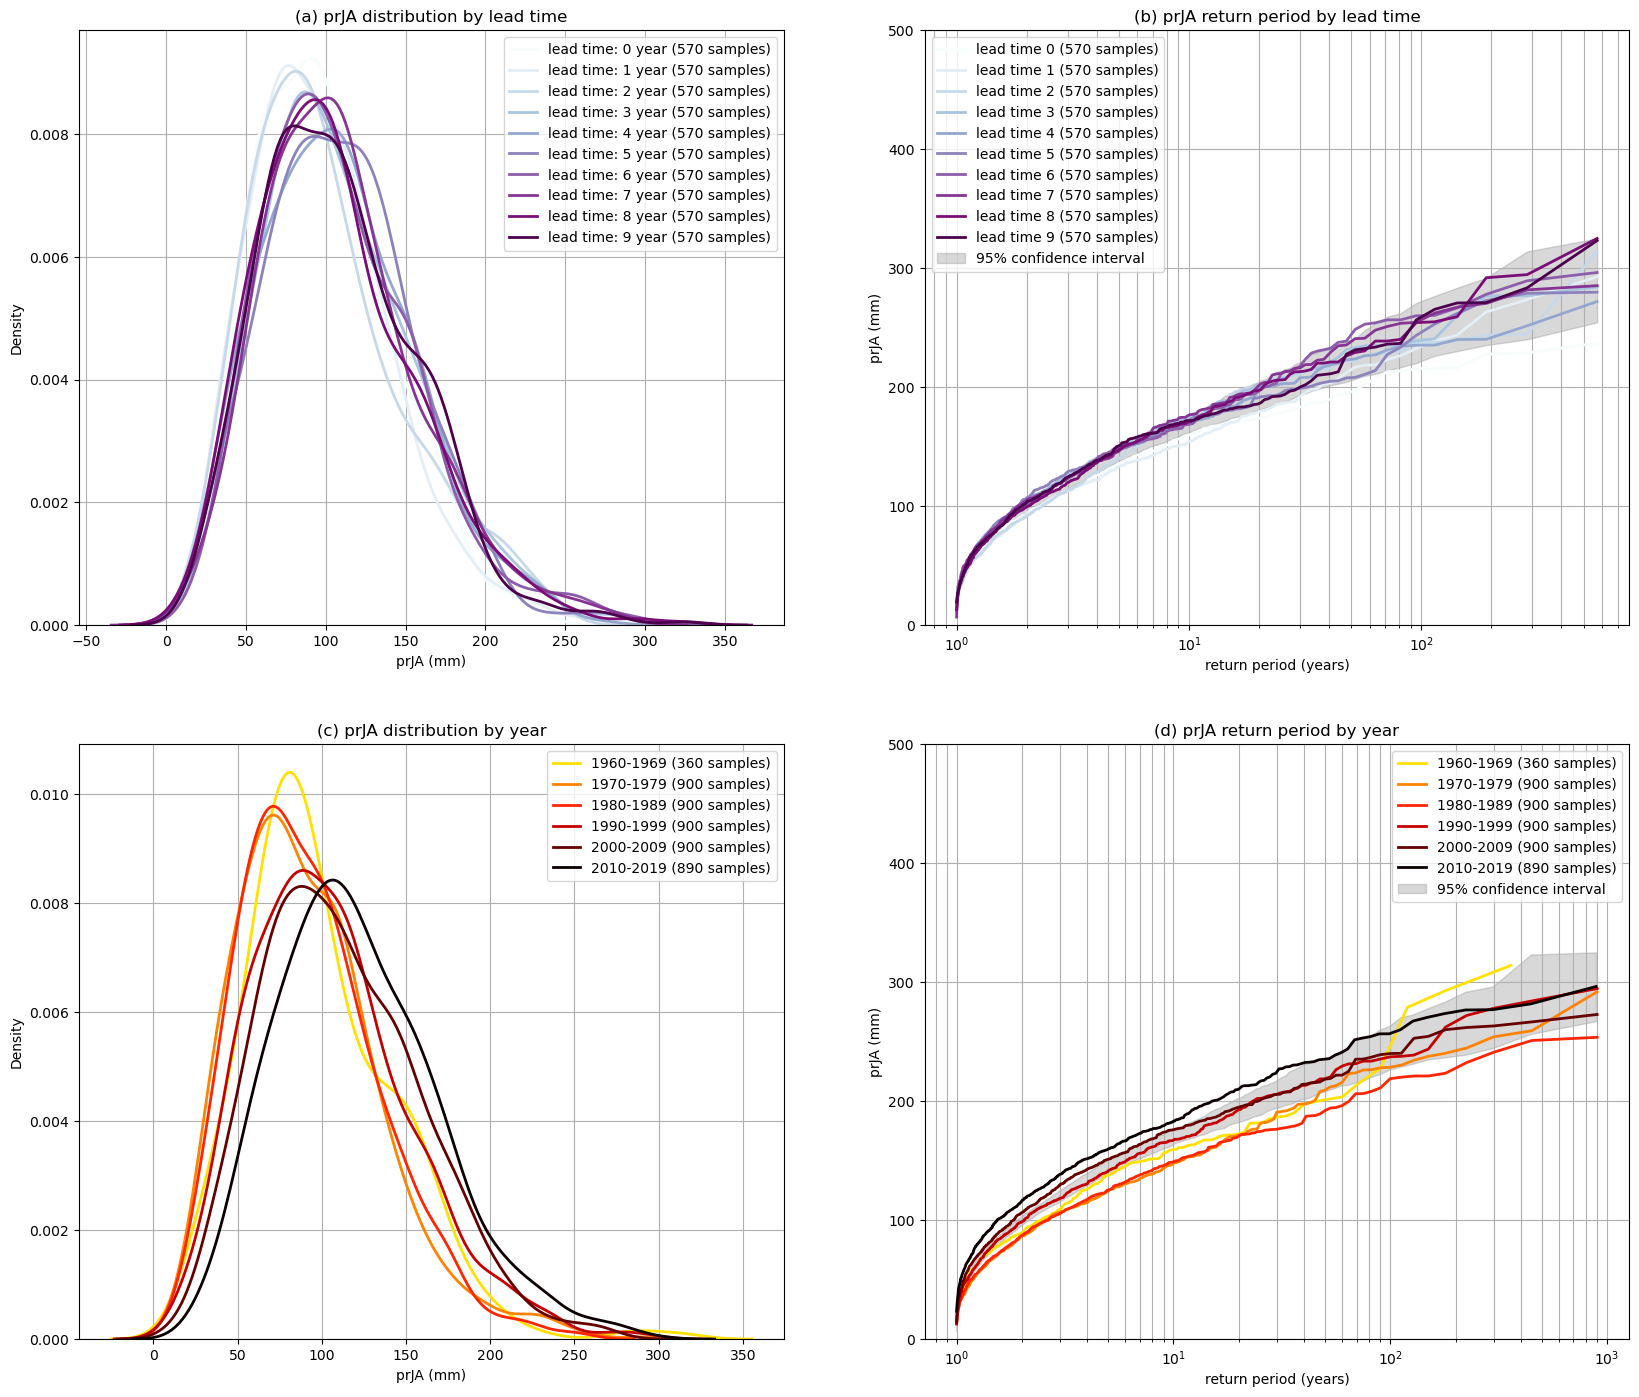

In [8]:
stability.create_plot(
    model_ds[var],
    metric,
    [1960, 1970, 1980, 1990, 2000, 2010],
    uncertainty=True,
    return_method='empirical',
    units=f'{metric} ({units})',
    ylim=(dist_min, dist_max),
)

#### Independence

In [9]:
independence_ds = independence.run_tests(model_ds[var])

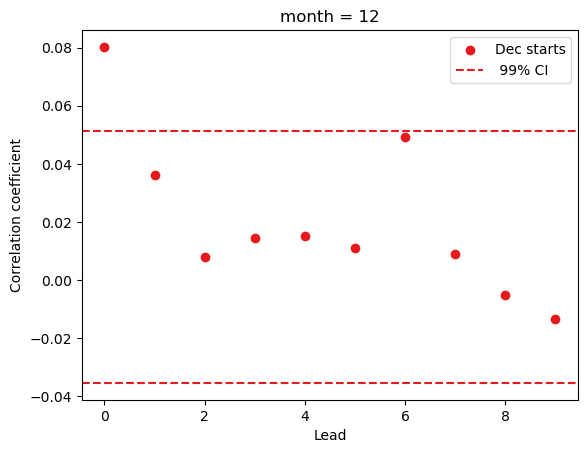

In [10]:
independence.point_plot(
    independence_ds,
    confidence_interval=0.99,
)

In [11]:
min_lead = 1

Drop lead times that aren't independent...

In [12]:
model_da_indep = model_ds[var].where(model_ds['lead_time'] >= min_lead)
model_da_indep = model_da_indep.dropna('lead_time')

In [13]:
model_da_indep_stacked = model_da_indep.stack({'sample': ['ensemble', 'init_date', 'lead_time']})

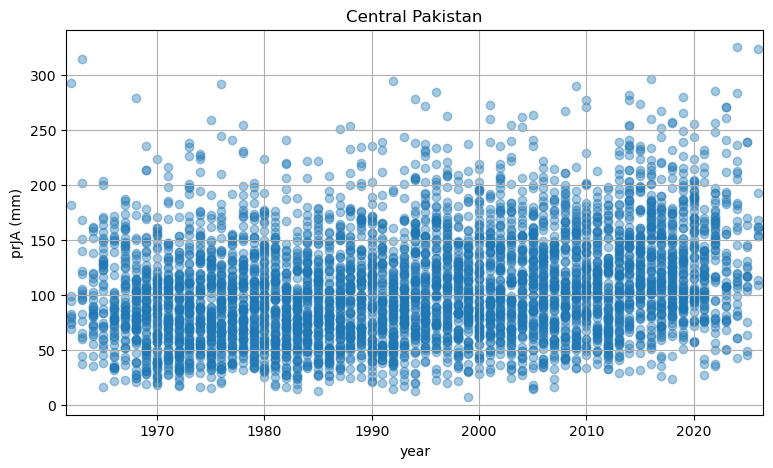

In [14]:
fig, ax = plt.subplots(figsize=[9, 5])
years = model_da_indep_stacked['time'].dt.year.values
unique_years = np.unique(model_da_indep_stacked.time.dt.year.values)

plt.scatter(
    years,
    model_da_indep_stacked.values,
    marker='o',
    color='tab:blue',
    alpha=0.4,
    label='raw data'
)
plt.xlim(unique_years[0] - 0.5, unique_years[-1] + 0.5)
plt.title(box_name)
plt.ylabel(f'{metric} ({units})')
plt.xlabel('year')
#plt.legend()
plt.grid()
plt.show()

#### Bias correction

In [15]:
bias = {}
bias_value = {}
for obs in obs_list:
    bias[obs] = bias_correction.get_bias(
        model_da_indep,
        obs_ds[obs][var],
        correction_method,
        time_rounding='A',
    )
    bias_value[obs] = bias[obs].values[0]
    print(f'{obs}: {bias_value[obs]:.2f}')

era5: 1.05
mswep: 1.13
cpc: 1.52


In [16]:
model_da_bc = {}
model_da_bc_stacked = {}
for obs in obs_list:
    model_da_bc[obs] = bias_correction.remove_bias(model_da_indep, bias[obs], correction_method)
    model_da_bc[obs] = model_da_bc[obs].compute()
    model_da_bc_stacked[obs] = model_da_bc[obs].stack({'sample': ['ensemble', 'init_date', 'lead_time']})

#### Similarity testing

In [17]:
def plot_dist(obs):
    """Plot distribution."""

    fig, ax = plt.subplots(figsize=[8, 5])
    xvals = np.arange(dist_min, dist_max, 0.1)

    title = f'{box_name} - full timeseries'
    model_da_indep.plot.hist(bins=20, density=True, alpha=0.7, facecolor='tab:blue', label='model (raw)')
    model_da_bc[obs].plot.hist(bins=50, density=True, alpha=0.7, facecolor='tab:orange', label='model (bias corrected)')
    obs_ds[obs][var].plot.hist(ax=ax, bins=50, density=True, facecolor='tab:gray', alpha=0.7, label=obs)
    
    plt.xlabel(f'{metric} ({units})')
    plt.ylabel('probability')
    plt.title(title)
    plt.xlim(dist_min, dist_max)
    plt.legend()
    plt.grid()
    plt.show()

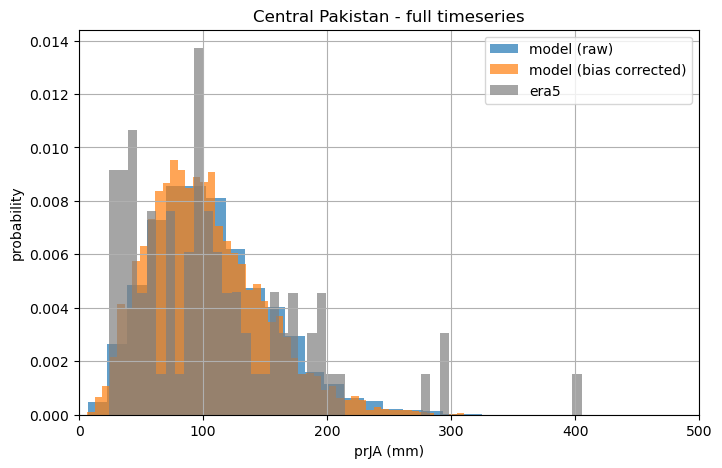

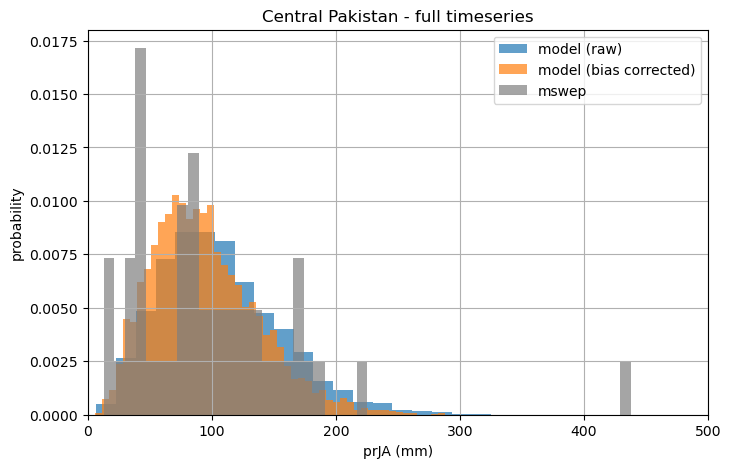

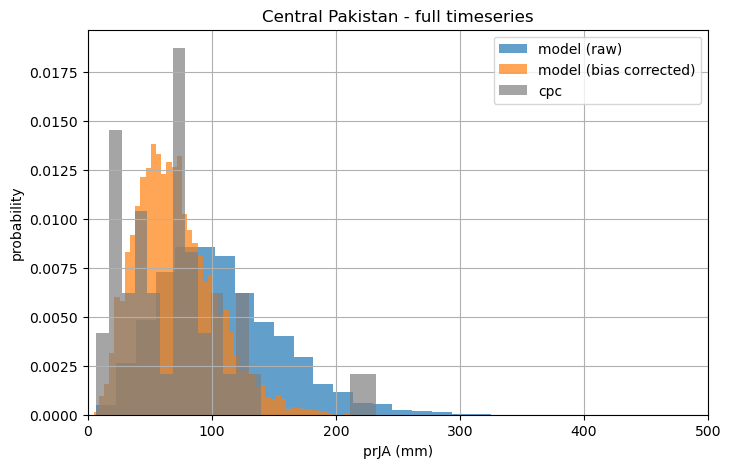

In [18]:
for obs in obs_list:
    plot_dist(obs)

In [19]:
similarity_ds_indep = {}
similarity_ds_bc = {}
ks_indep_pass = {}
ks_bc_pass = {}
for obs in obs_list:
    similarity_ds_indep[obs] = similarity.similarity_tests(model_da_indep, obs_ds[obs][var])
    ks_indep_pass[obs] = 'Pass' if similarity_ds_indep[obs]['ks_pval'].values > 0.05 else 'Fail'
    print(f'Raw model data vs {obs.upper()}:')
    print('  KS score:', similarity_ds_indep[obs]['ks_statistic'].values)
    print('  KS p-value:', f'{similarity_ds_indep[obs]['ks_pval'].values} ({ks_indep_pass[obs]})')
    print('  AD score:', similarity_ds_indep[obs]['ad_statistic'].values)
    print('  AD p-value:', similarity_ds_indep[obs]['ad_pval'].values)
    
    similarity_ds_bc[obs] = similarity.similarity_tests(model_da_bc[obs], obs_ds[obs][var])
    ks_bc_pass[obs] = 'Pass' if similarity_ds_bc[obs]['ks_pval'].values > 0.05 else 'Fail'
    print(f'Bias corrected model data vs {obs.upper()}:')
    print('  KS score:', similarity_ds_bc[obs]['ks_statistic'].values)
    print('  KS p-value:', f'{similarity_ds_bc[obs]['ks_pval'].values} ({ks_bc_pass[obs]})')
    print('  AD score:', similarity_ds_bc[obs]['ad_statistic'].values)
    print('  AD p-value:', similarity_ds_bc[obs]['ad_pval'].values)

Raw model data vs ERA5:
  KS score: 0.14678816
  KS p-value: 0.046918511390686035 (Fail)
  AD score: 4.126254
  AD p-value: 0.0072400374
Bias corrected model data vs ERA5:
  KS score: 0.13392267
  KS p-value: 0.0875176265835762 (Pass)
  AD score: 3.9285119
  AD p-value: 0.008584944
Raw model data vs MSWEP:
  KS score: 0.22945906
  KS p-value: 0.011041185818612576 (Fail)
  AD score: 4.3325763
  AD p-value: 0.006070051
Bias corrected model data vs MSWEP:
  KS score: 0.19339669
  KS p-value: 0.049391791224479675 (Fail)
  AD score: 2.2562227
  AD p-value: 0.03839163
Raw model data vs CPC:
  KS score: 0.3742524
  KS p-value: 2.3000936835160246e-06 (Fail)
  AD score: 20.764412
  AD p-value: 0.001
Bias corrected model data vs CPC:
  KS score: 0.14512463
  KS p-value: 0.2545582950115204 (Pass)
  AD score: 2.9173992
  AD p-value: 0.020977985


p > 0.05 means that the null hypothesis (that the two samples are from the same population) cannot be rejected.

#### Process assessment

In [20]:
def ensemble_to_run(model_name, ensnum):
    """Map ensemble number to DCPP model run"""

    norcpm_dict = {
        1: 'r1i1p1f1',
        2: 'r1i2p1f1',
        3: 'r2i1p1f1',
        4: 'r2i2p1f1',
        5: 'r3i1p1f1',
        6: 'r3i2p1f1',
        7: 'r4i1p1f1',
        8: 'r4i2p1f1',
        9: 'r5i1p1f1',
        10: 'r5i2p1f1',
        11: 'r6i1p1f1',
        12: 'r6i2p1f1',
        13: 'r7i1p1f1',
        14: 'r7i2p1f1',
        15: 'r8i1p1f1',
        16: 'r8i2p1f1',
        17: 'r9i1p1f1',
        18: 'r9i2p1f1',
        19: 'r10i1p1f1',
        20: 'r10i2p1f1',
    }

    ecearth_dict = {
        1: 'r1i1p1f1',
        2: 'r2i1p1f1',
        3: 'r3i1p1f1',
        4: 'r4i1p1f1',
        5: 'r5i1p1f1',
        6: 'r6i1p1f1',
        7: 'r6i2p1f1',
        8: 'r7i1p1f1',
        9: 'r7i2p1f1',
        10: 'r8i1p1f1',
        11: 'r8i2p1f1',
        12: 'r9i1p1f1',
        13: 'r9i2p1f1',
        14: 'r10i1p1f1',
        15: 'r10i2p1f1',
    }

    if model_name == 'EC-Earth3':
        run = ecearth_dict[ensnum]
    elif model_name == 'NorCPM1':
        run = norcpm_dict[ensnum]
    else:
        ensemble_to_run = { 
            'BCC-CSM2-MR': f'r{ensnum}i1p1f1',
            'CanESM5': f'r{ensnum}i1p2f1',
            'CMCC-CM2-SR5': f'r{ensnum}i1p1f1',
            'HadGEM3-GC31-MM': f'r{ensnum}i1p1f2',
            'IPSL-CM6A-LR': f'r{ensnum}i1p1f1',
            'MIROC6': f'r{ensnum}i1p1f1',
            'MPI-ESM1-2-HR': f'r{ensnum}i1p1f1',
            'MRI-ESM2-0': f'r{ensnum}i1p1f1',
        }
        run = ensemble_to_run[model_name]

    return run
    

def find_dcpp_data(event_df_row, model_name):
    """Find DCPP data for one row of a dataframe of events."""

    init_adjustment = {
        'BCC-CSM2-MR': 0,
        'CanESM5': -1,
        'CMCC-CM2-SR5': -1,
        'EC-Earth3': -1,
        'IPSL-CM6A-LR': -1,
        'MIROC6': -1,
        'MPI-ESM1-2-HR': -1,
        'MRI-ESM2-0': -1,
        'NorCPM1': -1,
    }

    assert model_name in init_adjustment
    
    init_date = int(event_df_row['init_date'].strftime('%Y')) + init_adjustment[model_name]
    ensemble = int(event_df_row['ensemble']) + 1
    run = ensemble_to_run(model_name, ensemble)
    event_year = event_df_row['time'].year
    event_value = round(float(event_df_row[var]), 1)
    event_summary = f'{metric} of {event_value} in the year {event_year}: initialisation year {init_date}, ensemble member {run}'
    print(event_summary)
    var_files = glob.glob(f'/g/data/oi10/replicas/CMIP6/DCPP/*/{model_name}/dcppA-hindcast/s{init_date}-{run}/day/{var}/*/*/*.nc')
    assert var_files
    psl_files = glob.glob(f'/g/data/oi10/replicas/CMIP6/DCPP/*/{model_name}/dcppA-hindcast/s{init_date}-{run}/day/psl/*/*/*.nc')
    zg500_files = glob.glob(f'/g/data/oi10/replicas/CMIP6/DCPP/*/{model_name}/dcppA-hindcast/s{init_date}-{run}/AERday/zg500/*/*/*.nc')

    return var_files, psl_files, zg500_files, event_year, event_value, event_summary

In [21]:
def event_check(da, event_value):
    """Check the event value"""

    da_box = da.sel(lat=slice(box_lat0, box_lat1), lon=slice(box_lon0, box_lon1))
    da_box_mean = spatial_selection.aggregate(da_box, 'weighted_mean')
    
    np.testing.assert_approx_equal(float(da_box_mean), event_value, significant=1)
    # np.testing.assert_approx_equal(float(da_box_mean) - bias_value, event_value, significant=1)


def get_event_data(event_df_row, model_name):
    """Plot an event"""

    infiles_var, infiles_psl, infiles_zg500, event_year, event_value, event_summary = find_dcpp_data(event_df_row, model_name)
    dcpp_config = '/home/599/dbi599/unseen-projects/dataset_config/dataset_dcpp.yml'

    start_date = f'{event_year}-07-01'
    end_date = f'{event_year}-08-31'

    ds_var = fileio.open_dataset(infiles_var, metadata_file=dcpp_config)
    ds_var = ds_var.sel(
        time=slice(start_date, end_date),
        lat=slice(region_lat0 - 5, region_lat1 + 5),
        lon=slice(region_lon0 - 5, region_lon1 + 5),
    )
    da_var = general_utils.convert_units(ds_var[var], units)
    da_var = da_var.sum('time', keep_attrs=True)
#    da_var.attrs['units'] = units
    event_check(da_var, event_value)

    if infiles_psl:
        ds_psl = fileio.open_dataset(infiles_psl, metadata_file=dcpp_config)
        ds_psl = ds_psl.sel(
            time=slice(start_date, end_date),
            lat=slice(region_lat0 - 5, region_lat1 + 5),
            lon=slice(region_lon0 - 5, region_lon1 + 5),
        )
        da_psl = general_utils.convert_units(ds_psl['psl'], 'hPa')
        da_psl = da_psl.mean('time', keep_attrs=True)
    else:
        da_psl = None
    
    if infiles_zg500:
        ds_zg500 = fileio.open_dataset(infiles_zg500, metadata_file=dcpp_config)
        ds_zg500 = ds_zg500.sel(
            time=slice(start_date, end_date),
            lat=slice(region_lat0 - 5, region_lat1 + 5),
            lon=slice(region_lon0 - 5, region_lon1 + 5),
        )
        da_zg500 = ds_zg500['zg500']
        da_zg500 = da_zg500.mean('time', keep_attrs=True)
    else:
        da_zg500 = None

    return da_var, da_psl, da_zg500

In [22]:
def plot_event(da_var, da_contour, contour_var):
    """Plot event."""

    assert contour_var in ['psl', 'zg500']
    
    fig = plt.figure(figsize=[15, 5])
    ax = fig.add_subplot(111, projection=map_proj)
    
    da_var.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=var_cmap,
        levels=levels_dict[var],
        extend='max',
    #    cbar_kwargs={"label": label},
    )
    if type(da_contour) != type(None):
        lines = da_contour.plot.contour(
            ax=ax,
            transform=ccrs.PlateCarree(),
            levels=levels_dict[contour_var],
            colors=["0.3"]
        )
        ax.clabel(lines, colors=["0.3"], manual=False, inline=True)
    
    ax.plot(
        [box_lon0, box_lon0, box_lon1, box_lon1, box_lon0],
        [box_lat1, box_lat0, box_lat0, box_lat1, box_lat1],
        transform=ccrs.PlateCarree(),
        color='green',
    )   
    ax.coastlines()
    #ax.set_extent([180, 300, 30, 70], crs=ccrs.PlateCarree(central_longitude=0))
    ax.add_feature(cartopy.feature.BORDERS)
    ax.gridlines(linestyle="--", draw_labels=True)
    
    plt.show()

In [23]:
model_da_indep_stacked_df = model_da_indep_stacked.to_dataframe()
nsamples = len(model_da_indep_stacked_df)
model_da_indep_stacked_df.index = range(1, nsamples + 1)
model_da_indep_stacked_df_sorted = model_da_indep_stacked_df.sort_values(by=[var], ascending=False)
model_da_indep_stacked_df_sorted.head(n=10)

,time,ensemble,init_date,lead_time,pr
4094,2024-12-31 00:00:00,7,2016-12-31 00:00:00,8,324.985474
3078,2026-12-31 00:00:00,5,2017-12-31 00:00:00,9,323.161560
2054,1963-12-31 00:00:00,4,1961-12-31 00:00:00,2,314.033691
3012,2016-12-31 00:00:00,5,2010-12-31 00:00:00,6,296.321655
1754,1992-12-31 00:00:00,3,1984-12-31 00:00:00,8,294.552185
2053,1962-12-31 00:00:00,4,1961-12-31 00:00:00,1,292.850098
3662,1976-12-31 00:00:00,7,1968-12-31 00:00:00,8,291.917114
1410,2009-12-31 00:00:00,2,2003-12-31 00:00:00,6,289.332275
4084,2022-12-31 00:00:00,7,2015-12-31 00:00:00,7,285.257538
291,1996-12-31 00:00:00,0,1993-12-31 00:00:00,3,284.168396


In [24]:
nsamples = len(model_da_indep_stacked_df)
print(f'Total number of samples: {nsamples}')

Total number of samples: 5130


prJA of 325.0 in the year 2024: initialisation year 2015, ensemble member r8i1p1f1


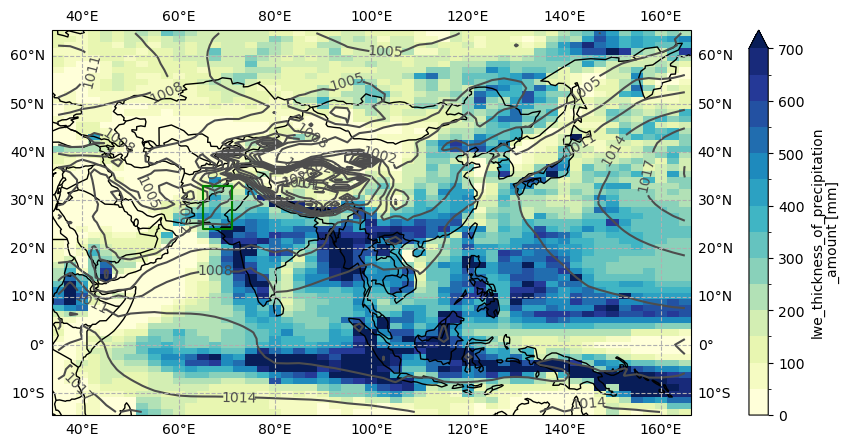

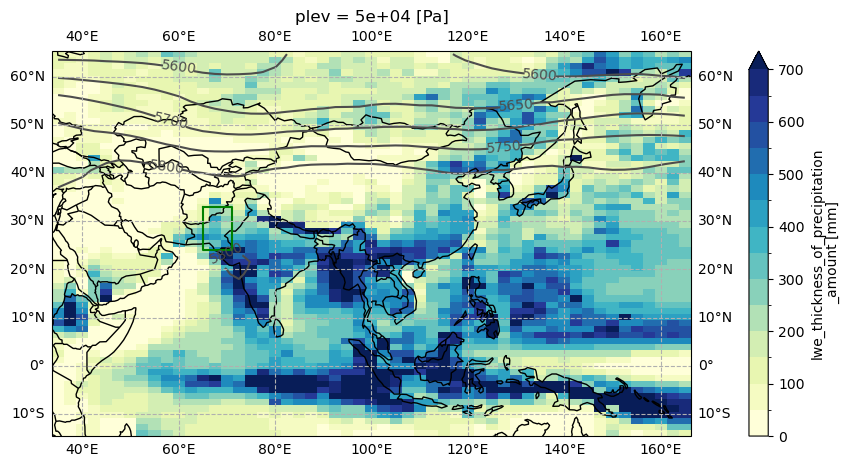

prJA of 323.2 in the year 2026: initialisation year 2016, ensemble member r6i1p1f1


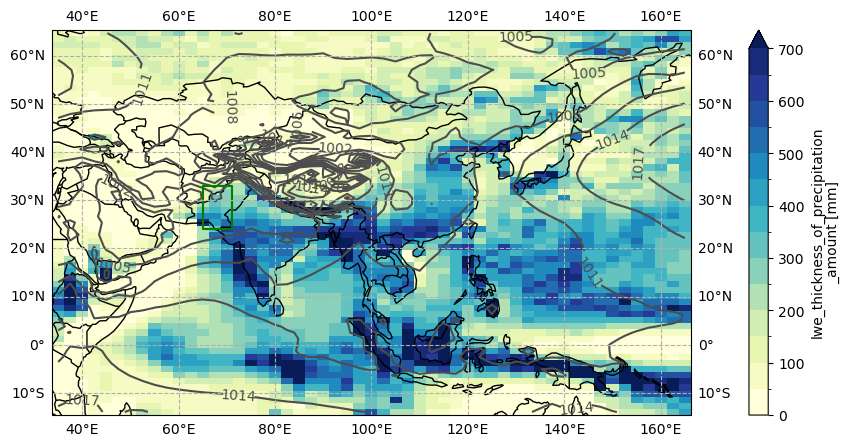

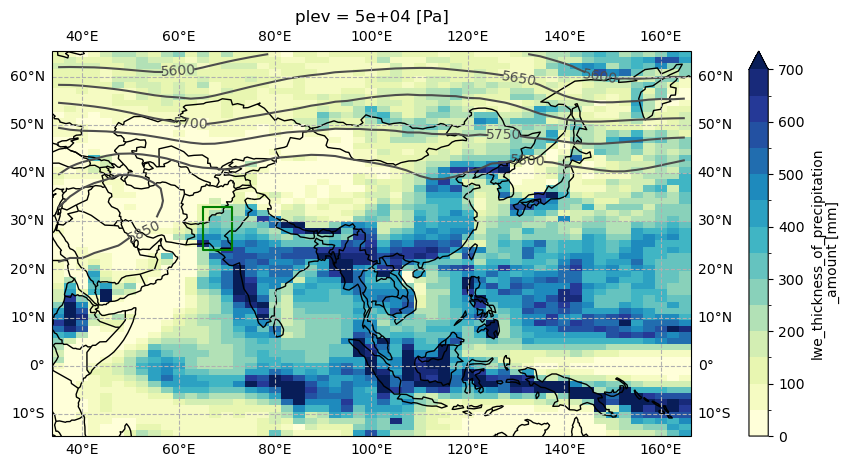

prJA of 314.0 in the year 1963: initialisation year 1960, ensemble member r5i1p1f1


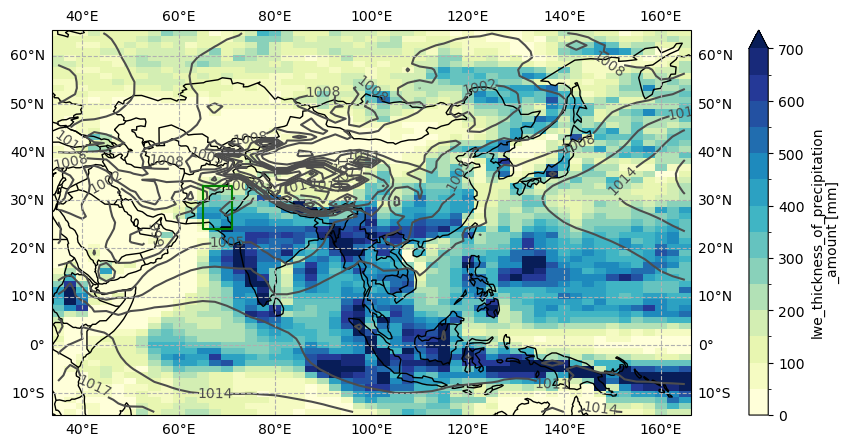

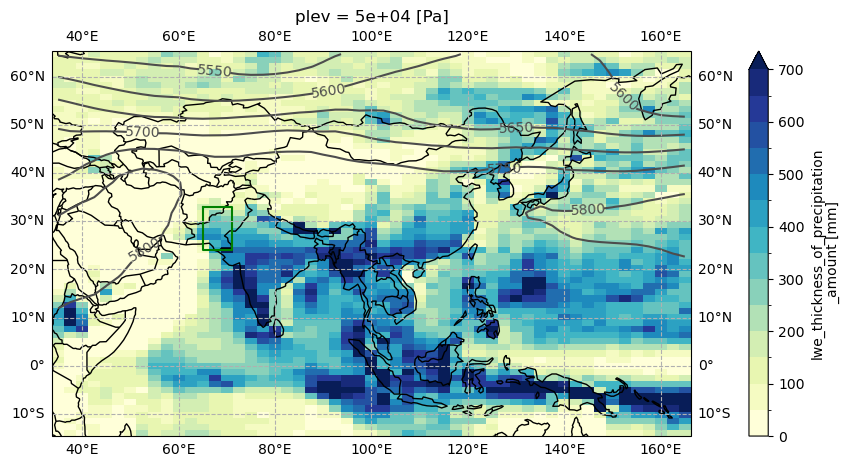

prJA of 296.3 in the year 2016: initialisation year 2009, ensemble member r6i1p1f1


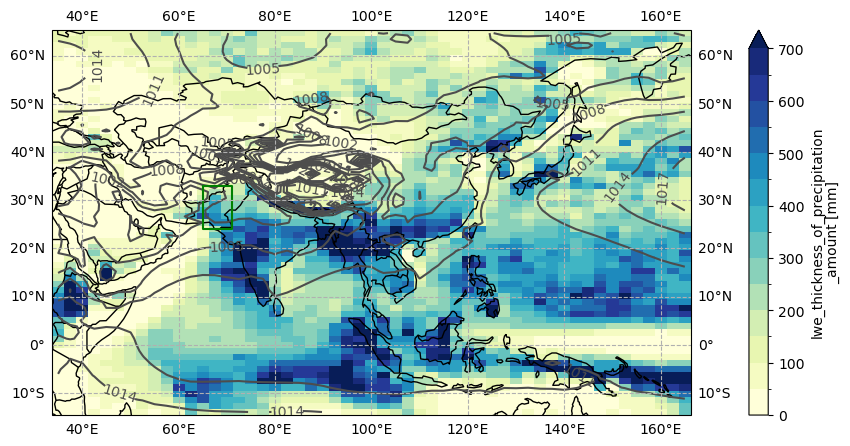

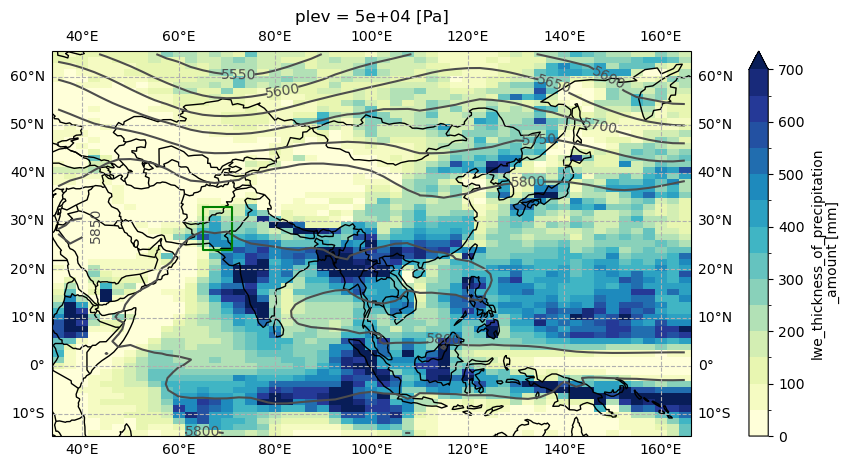

prJA of 294.6 in the year 1992: initialisation year 1983, ensemble member r4i1p1f1


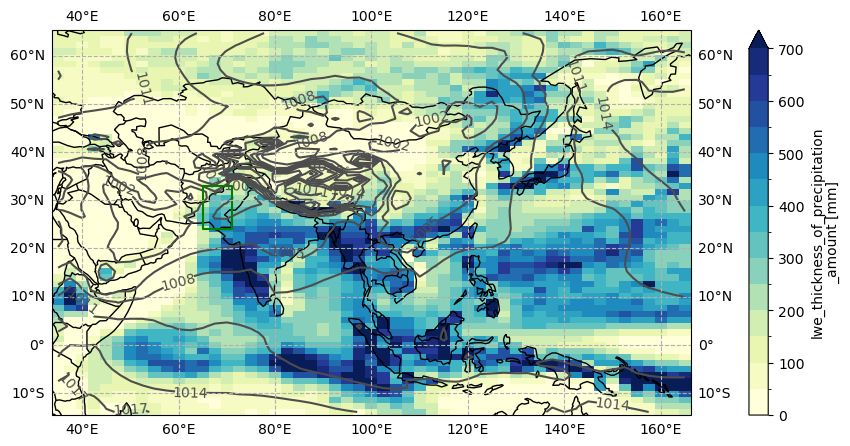

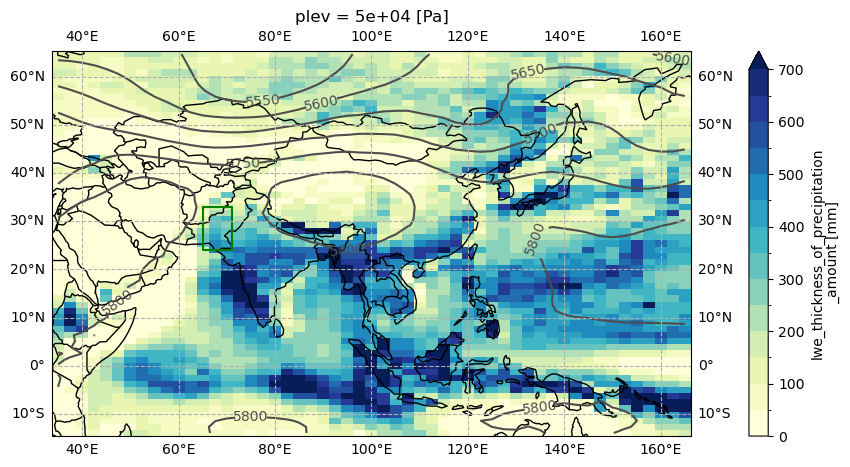

prJA of 292.9 in the year 1962: initialisation year 1960, ensemble member r5i1p1f1


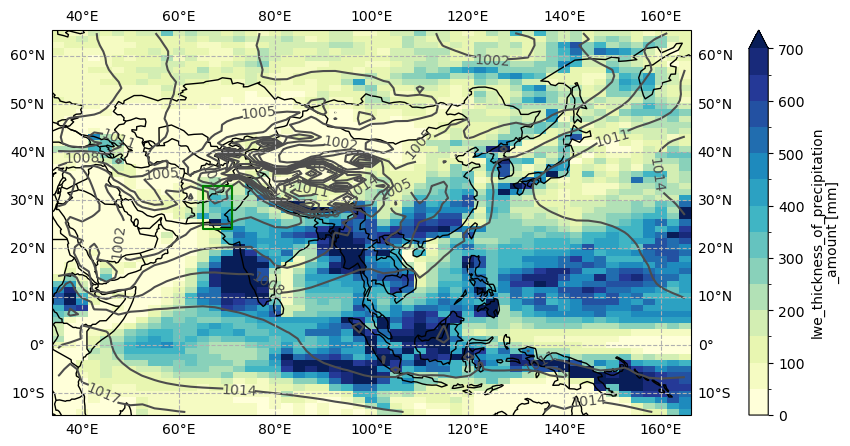

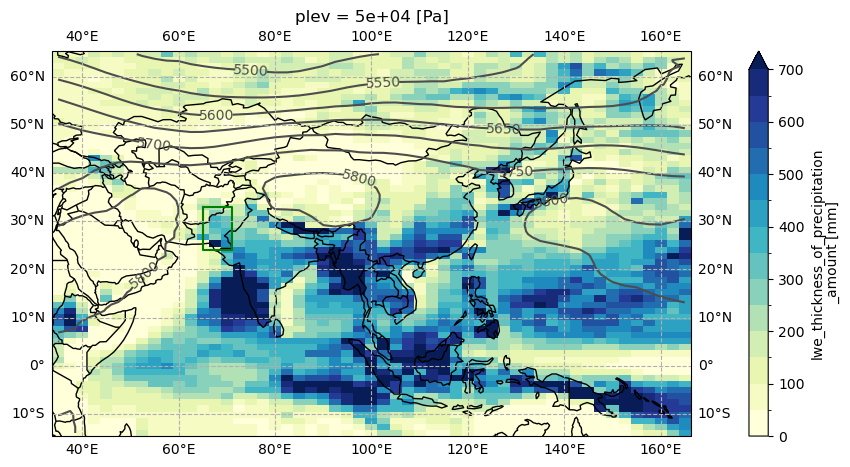

prJA of 291.9 in the year 1976: initialisation year 1967, ensemble member r8i1p1f1


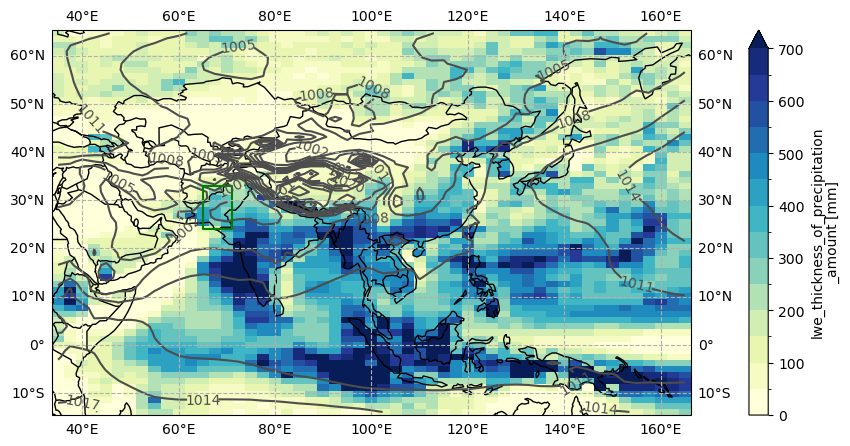

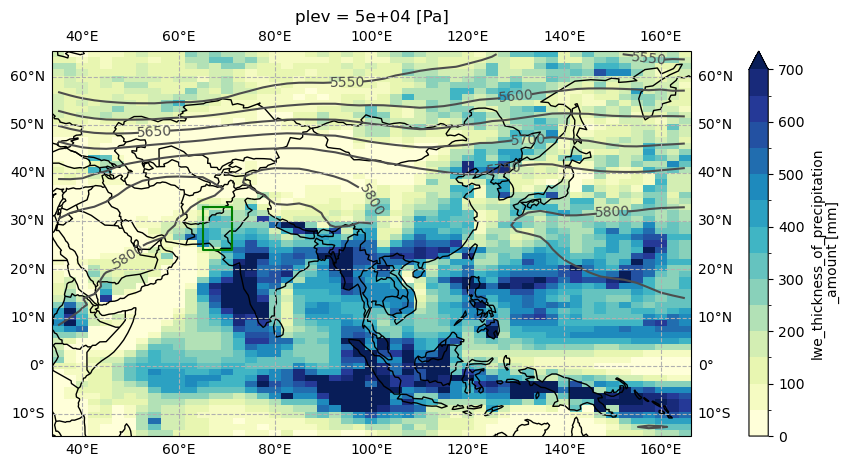

prJA of 289.3 in the year 2009: initialisation year 2002, ensemble member r3i1p1f1


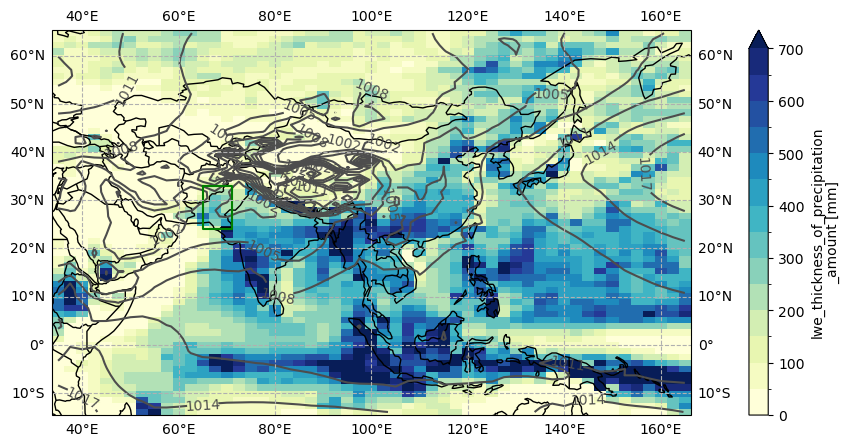

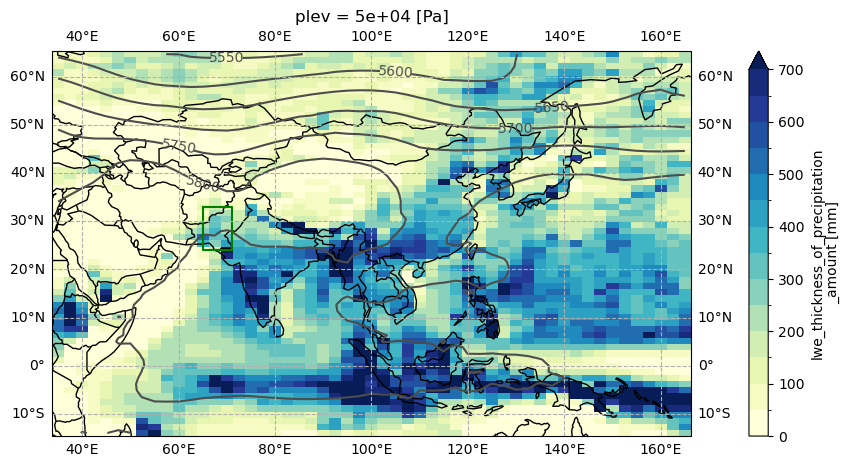

prJA of 285.3 in the year 2022: initialisation year 2014, ensemble member r8i1p1f1


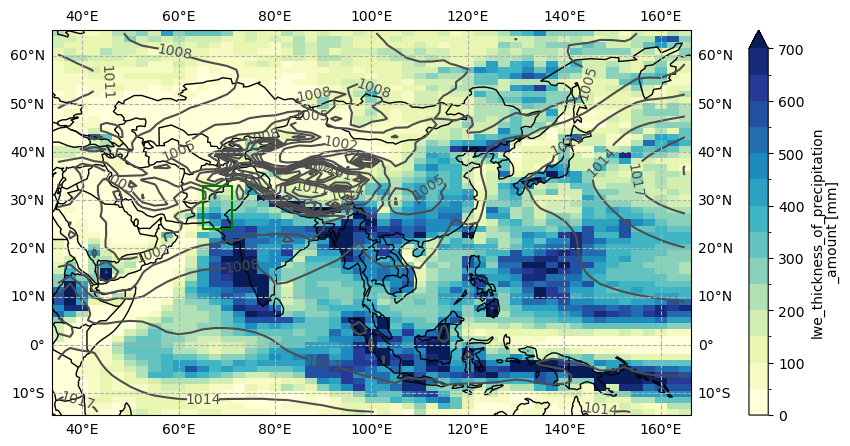

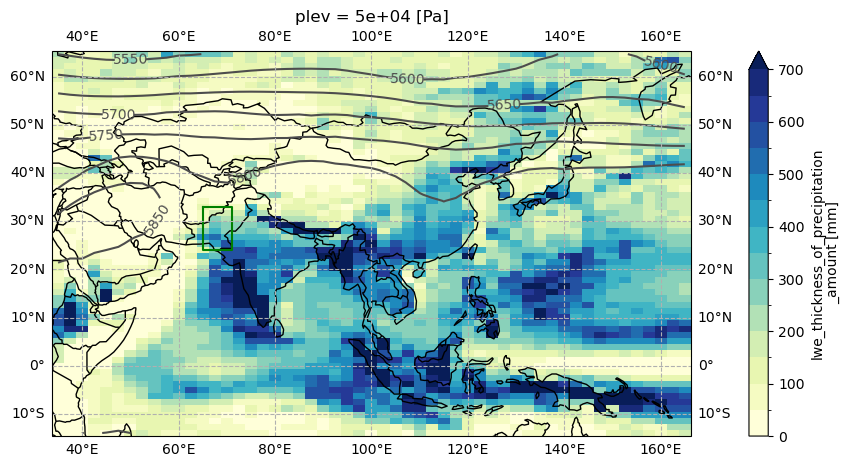

prJA of 284.2 in the year 1996: initialisation year 1992, ensemble member r1i1p1f1


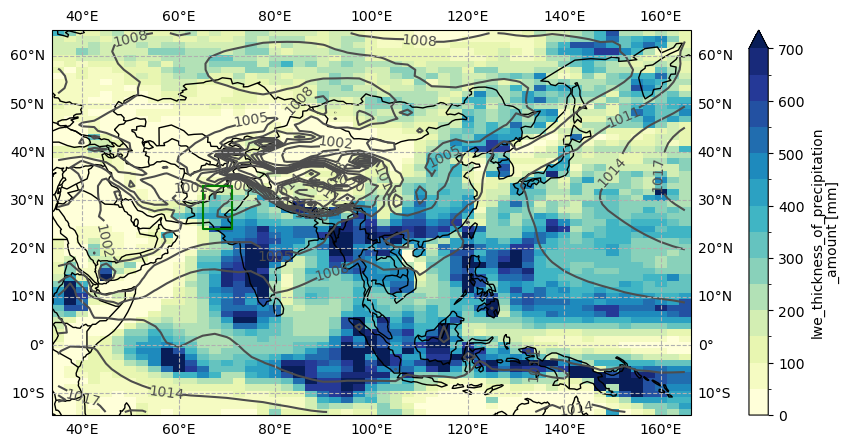

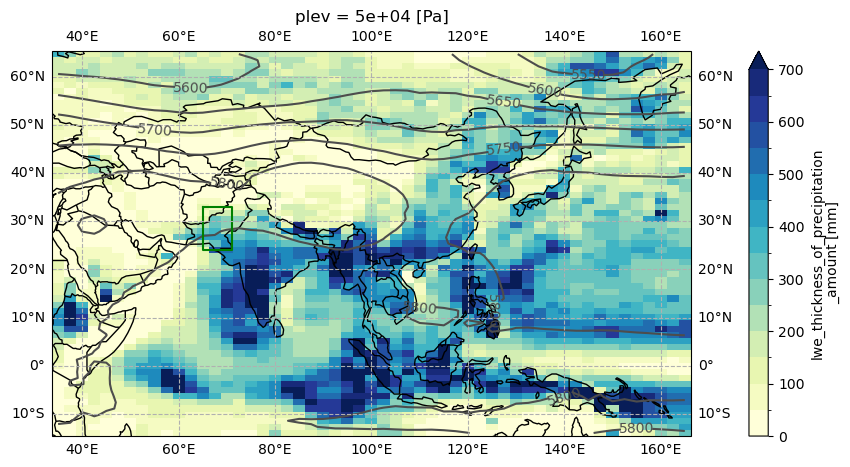

In [25]:
da_var_dict = {}
da_psl_dict = {}
da_zg500_dict = {}
for rank in range(10):
    number = model_da_indep_stacked_df_sorted.iloc[rank].name
    da_var_dict[number], da_psl_dict[number], da_zg500_dict[number] = get_event_data(
        model_da_indep_stacked_df_sorted.iloc[rank], model
    )
    plot_event(da_var_dict[number], da_psl_dict[number], 'psl')
    plot_event(da_var_dict[number], da_zg500_dict[number], 'zg500')

## Results

#### Extreme value analysis

In [26]:
def calc_return_period(model_da_samples_stacked, event):
    """Perform extreme value analysis"""

    return_period = eva.get_empirical_return_period(model_da_samples_stacked, event, core_dim="sample")
    
    # non-parametric uncertainty estimate
    n_bootstraps = 1000
    sample_size = len(model_da_samples_stacked)
    boot_samples = []
    for i in range(n_bootstraps):
        rng = np.random.default_rng()
        resample_indices = rng.choice(sample_size, size=sample_size, replace=True)
        boot_data = model_da_samples_stacked.isel({'sample': resample_indices})        
        boot_return_period = eva.get_empirical_return_period(boot_data, event, core_dim="sample")
        boot_samples.append(boot_return_period)
    ci05 = np.percentile(boot_samples, 5)
    ci16 = np.percentile(boot_samples, 16)
    ci84 = np.percentile(boot_samples, 84)
    ci95 = np.percentile(boot_samples, 95)

    print(f'The return period of a {event:.2f} {units} event is {return_period:.0f} years.')
    print(f'The 5-95% confidence interval is {ci05:.0f} to {ci95:.0f} years.')
    print(f'The 16-84% confidence interval is {ci16:.0f} to {ci84:.0f} years.')

In [27]:
step_bias = {}
for obs in obs_list:
    if ks_indep_pass[obs] == 'Pass':
        step_bias[obs] = f'No bias correction was applied to the {metric} values.'
        print(f'{obs.upper()}: raw data passes the similarity test')
        calc_return_period(model_da_indep_stacked, obs_2022_event[obs])
    elif ks_bc_pass[obs] == 'Pass':
        step_bias[obs] = f'Applied bias correction to the {metric} values (multiplicative scaling relative to the {obs_name[obs]} observational dataset).'
        print(f'{obs.upper()}: bias correction passes the similarity test')
        calc_return_period(model_da_bc_stacked[obs], obs_2022_event[obs])
    else:
        print(f'{obs.upper()}: data fails similarity test before and after bias correction')

ERA5: bias correction passes the similarity test
The return period of a 405.26 mm event is inf years.
The 5-95% confidence interval is nan to nan years.
The 16-84% confidence interval is nan to nan years.
MSWEP: data fails similarity test before and after bias correction
CPC: bias correction passes the similarity test
The return period of a 518.59 mm event is inf years.
The 5-95% confidence interval is nan to nan years.
The 16-84% confidence interval is nan to nan years.


## Supporting data

In [28]:
ecmwf_attrs = {}
ecmwf_attrs['pr'] = {
    'name': 'tp',
    'units': 'mm',
    'long_name': 'July-August accumulated rainfall',
}
ecmwf_attrs['psl'] = {
    'name': 'msl',
    'units': 'Pa',
    'long_name': 'Mean sea level pressure',
}
ecmwf_attrs['zg500'] = {
    'name': 'gh500',
    'units': 'm',
    'long_name': 'Geopotential height at 500 hPa',
}

### Tier 2 data

In [29]:
def write_tier2_data(model_da_samples_stacked, obs_dataset, bc=False):
    """Write Tier 2 data file"""

    model_da_samples_stacked_df = model_da_samples_stacked.to_dataframe()
    nsamples = len(model_da_samples_stacked_df)
    model_da_samples_stacked_df.index = range(1, nsamples + 1)
    
    numbers = model_da_samples_stacked_df.index.values
    da1 = xr.DataArray(
        data=np.round(model_da_samples_stacked_df[var].values, 2),
        coords={'number': numbers,},
        name=metric,
        attrs = {
            'long_name': metric_long,
            'units': units,
        }
    )
    da1 = general_utils.convert_units(da1, ecmwf_attrs[var]['units'])

    try:
        del da1.attrs['units_metadata']
    except KeyError:
        pass
    
    years = [t.year for t in model_da_samples_stacked_df['time'].values]
    da2 = xr.DataArray(
        data=years,
        coords={'number': numbers,},
        name='year',
        attrs = {
            'long_name': 'year',
        }
    )

    output_ds = xr.merge([da1, da2])
    output_ds.attrs = global_attrs
    output_ds.attrs['data_tier'] = 'tier2'
    step_download = 'Downloaded daily precipitation data (pr).'
    step_spatial_selection = 'Selected the central Pakistan domain (24-33N, 65-71E).'
    step_spatial_aggregation = 'Computed the cosine-latitude-weighted spatial mean.'
    step_temporal_aggregation = 'Selected the July and August months. Resampled to annual sum.'
    step_independence = f'Dropped lead times that are not independent (< {min_lead} years).'
    output_ds.attrs['processing'] = f'{step_download} {step_spatial_selection} {step_spatial_aggregation} {step_temporal_aggregation} {step_independence} {step_bias[obs_dataset]}'
    output_ds['number'].attrs['long_name'] = 'Sample number'

    if bc:
        output_ds.attrs['references'] = global_attrs['references'] + f'. {obs_dataset.upper()} dataset: {obs_source[obs_dataset]}' 
    fname = f'{outdir}/CSIRO_UNSEEN_tier2_{model}-{obs_dataset.upper()}.nc'
    encoding = get_encoding(output_ds)
#    encoding['event_date']['units'] = 'days since 1960-01-01'
    output_ds.to_netcdf(fname, encoding=encoding)
    print(fname)

In [30]:
for obs in obs_list:
    if ks_indep_pass[obs] == 'Pass':
        write_tier2_data(model_da_indep_stacked, obs, bc=False)
    elif ks_bc_pass[obs] == 'Pass':
        write_tier2_data(model_da_bc_stacked[obs], obs, bc=True)

/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/CSIRO_UNSEEN_tier2_IPSL-CM6A-LR-ERA5.nc
/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/CSIRO_UNSEEN_tier2_IPSL-CM6A-LR-CPC.nc


### Tier 3 data

In [31]:
similarity_results = list(ks_indep_pass.values()) + list(ks_bc_pass.values())

#### JA means

In [32]:
def ceaa_format(da, variable, number=None):
    """Modify an array so if conforms with the requested CEAA format"""

    try:
        da = da.drop_vars('height')
    except ValueError:
        pass

    try:
        da = da.drop_vars('plev')
    except ValueError:
        pass

    da = general_utils.convert_units(da, ecmwf_attrs[variable]['units'])

    da = da.rename({'lat': 'latitude', 'lon': 'longitude'})
    da.name = ecmwf_attrs[variable]['name']
    da.attrs = {}
    da.attrs['long_name'] = ecmwf_attrs[variable]['long_name']
    da.attrs['units'] = ecmwf_attrs[variable]['units']

    if number:
        da['number'] = number
        da['number'].attrs['long_name'] = 'Sample number'

    return da

In [33]:
if 'Pass' in similarity_results:
    da_psl_list = []
    da_zg500_list = []
    skip_vars = []
    for number, da_var in da_var_dict.items():
        da_var_ceaa = ceaa_format(da_var, var, number=number)
        
        da_psl = da_psl_dict[number]
        if type(da_psl) == type(None):
            print(f'missing psl data for sample number {number}') 
            da_psl_ceaa = da_var_ceaa * np.nan
            da_psl_ceaa.name = ecmwf_attrs['psl']['name']
            da_psl_ceaa.attrs['long_name'] = ecmwf_attrs['psl']['long_name']
            da_psl_ceaa.attrs['units'] = ecmwf_attrs['psl']['units']
            skip_vars.append('msl')
        else:
            da_psl_ceaa = ceaa_format(da_psl, 'psl', number=number)
        da_psl_list.append(da_psl_ceaa)
    
        da_zg500 = da_zg500_dict[number]
        if type(da_zg500) == type(None):
            print(f'missing zg500 data for sample number {number}') 
            da_zg500_ceaa = da_var_ceaa * np.nan
            da_zg500_ceaa.name = ecmwf_attrs['zg500']['name']
            da_zg500_ceaa.attrs['long_name'] = ecmwf_attrs['zg500']['long_name']
            da_zg500_ceaa.attrs['units'] = ecmwf_attrs['zg500']['units']
            skip_vars.append('gh500')
        else:
            da_zg500_ceaa = ceaa_format(da_zg500, 'zg500', number=number)
        da_zg500_list.append(da_zg500_ceaa)
    
    ds_psl = xr.concat(da_psl_list, dim='number')
    ds_zg500 = xr.concat(da_zg500_list, dim='number')
    skip_vars = list(set(skip_vars))
    
    ds = xr.merge([ds_psl, ds_zg500])
    ds.attrs = global_attrs
    ds.attrs['data_tier'] = 'tier3'
    step_download_spatial_select = 'Downloaded daily mean sea level pressure (psl) and 500hPa geopotential height (zg500) data over the 10S-60N, 40-160E domain.' 
    step_tstep_select = f'Selected the July-August data associated with the top ten most extreme {metric} events. Calculated the July-August mean psl and zg500 for each event.'
    ds.attrs['processing'] = f'{step_download_spatial_select} {step_tstep_select}'
    encoding = get_encoding(ds, skip_vars=skip_vars)
    outfname = f'{outdir}/CSIRO_UNSEEN_tier3_{model}_JA-mean.nc'
    ds.to_netcdf(outfname, encoding=encoding)
    print(outfname)

/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/CSIRO_UNSEEN_tier3_IPSL-CM6A-LR_JA-mean.nc
